In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")

# Convertir las columnas de fechas de orders

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# 1 Categorías de productos

Utilizando la tabla de productos, determina cuántos productos existen en cada categoría.

Construye una gráfica de barras que muestre las categorías con mayor cantidad de productos.

Pregunta: ¿Qué categorías tienen mayor presencia en el catálogo de Olist?

Requisitos:

Ordena las categorías de mayor a menor.

Agrega un título.

Etiqueta correctamente los ejes.

Utiliza un color para las barras.

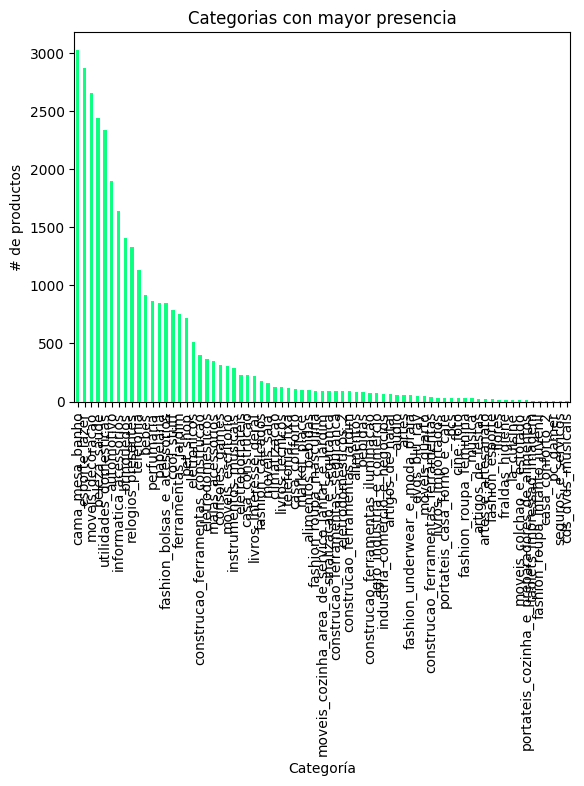

In [15]:
numero_productos = products["product_category_name"].value_counts()
ax1 = numero_productos.plot(kind="bar",
                title = "Categorias con mayor presencia",
                xlabel = "Categoría",
                ylabel = "# de productos",
                rot = 90,
                color = "#0dff82")
plt.show()

Las categorías que tienen mayor presencia son: "cama_mesa_banho","esporte_lazer","moveis_decoracao","beleza_saude","utilidades_domesticas"

##### PD. Esto es imposible de leer 

# 2 Las 10 categorías principales

La cantidad de categorías de Olist puede hacer que una gráfica sea difícil de leer.

Construye una gráfica de barras mostrando únicamente las 10 categorías con mayor número de productos.

Pregunta: ¿Cuáles son las categorías que tienen mayor presencia en el catálogo?

Requisitos:

Utiliza barras horizontales si consideras que facilitan la lectura.

Ordena los resultados.

Incluye título y etiquetas.


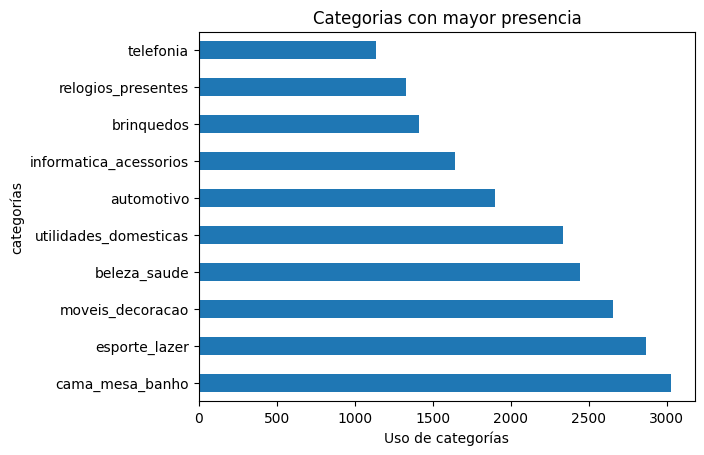

In [16]:
ax1 = numero_productos.head(10).plot(kind="barh",
                title = "Categorias con mayor presencia",
                rot = 0,
                xlabel = "Uso de categorías",
                ylabel = "categorías")
plt.show()

Las categorías que tienen mayor presencia son: "cama_mesa_banho","esporte_lazer","moveis_decoracao","beleza_saude","utilidades_domesticas"

#### Esto sí es legible

# 3 Distribución de productos

Construye un pie chart que muestre cómo se distribuyen los productos entre las categorías.

Para evitar una gráfica ilegible, utiliza solamente las 5 categorías con mayor número de productos y agrupa todas las demás como "Otros".

Pregunta: ¿Qué proporción del catálogo está concentrada en las principales categorías?

Requisitos:

Mostrar porcentajes.

Etiquetar las categorías.

Agregar un título.

Utilizar colores diferentes.


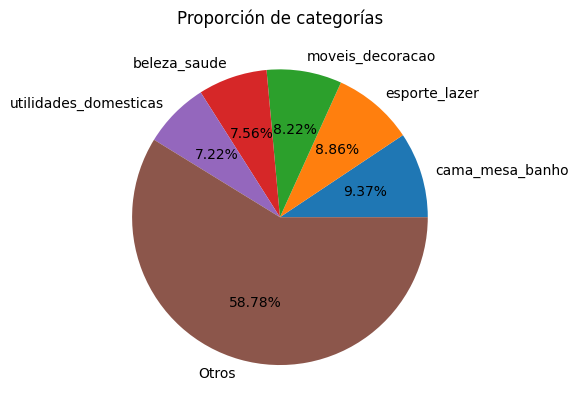

In [17]:
numero_productos = products["product_category_name"].value_counts().head(5)
numero_productos["Otros"] = products["product_category_name"].value_counts().iloc[5:].sum()
ax2 = numero_productos.plot(kind = "pie",
                            autopct="%1.2f%%",
                            color = "",
                            title = "Proporción de categorías",
                            ylabel = "")
plt.show()

Las 5 categorías principales concentran 41% del catálogo, y ninguna pasa de 9.5%. El 58.78% restante se reparte entre todas las demás categorías, así que aunque 5 categorías destacan, más de la mitad del catálogo está fuera de ellas.

# 4 Clientes por estado

Utilizando la información de los clientes, determina cuántos clientes existen en cada estado de Brasil.

Construye una gráfica de barras con los estados ordenados de mayor a menor cantidad de clientes.

Pregunta: ¿Qué estados concentran la mayor cantidad de clientes?

Requisitos:

Mostrar todos los estados.

Ordenar de mayor a menor.

Utilizar barras horizontales.

Agregar título y etiquetas.

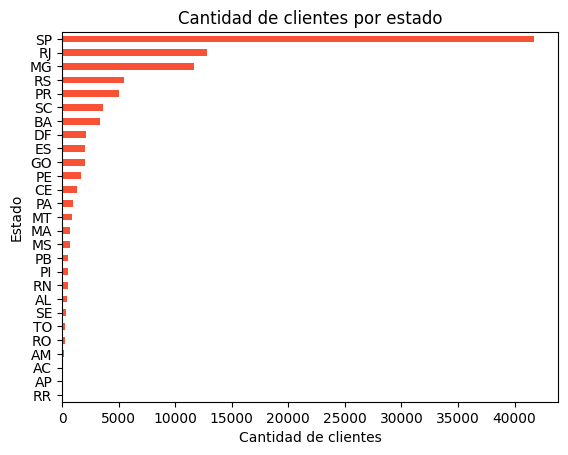

In [18]:
cantidad_clientes = customers["customer_state"].value_counts().sort_values(ascending= True)
ax3 = cantidad_clientes.plot(kind="barh",
                             title = "Cantidad de clientes por estado",
                             color = "#f75235",
                             xlabel="Cantidad de clientes",
                             ylabel= "Estado")
plt.show()

Los estados que mas concentran clientes son SP, RJ y MG

# 5 Estados principales

Construye un pie chart con los 5 estados que concentran mayor cantidad de clientes.

Agrupa todos los demás estados en una categoría llamada "Otros".

Pregunta: ¿Qué tan concentrada está la base de clientes geográficamente?

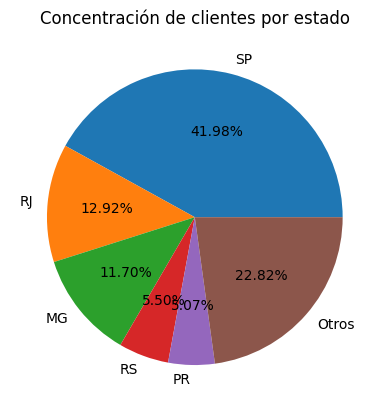

In [19]:
cantidad_clientes2 = customers["customer_state"].value_counts()
top5 = cantidad_clientes2.head(5)
top5["Otros"] = cantidad_clientes2.iloc[5:].sum()
ax5 = top5.plot(kind="pie",
                autopct = "%1.2f%%",
                title = "Concentración de clientes por estado",
                ylabel = "")

La mayoria de clientes se concentran en SP, RJ y MG con un 41.98%, 12.92% y 11.70% respectivamente

# 6 Métodos de pago

Utilizando la tabla de pagos, determina cuántos pagos fueron realizados mediante cada método de pago.

Construye primero una gráfica de barras.

Pregunta: ¿Cuál es el método de pago más utilizado?
Después construye un pie chart utilizando exactamente la misma información.

Reflexión:
¿Cuál de las dos gráficas permite comparar mejor los métodos de pago?

¿Cuál utilizarías si quisieras enfatizar la proporción que representa cada método?

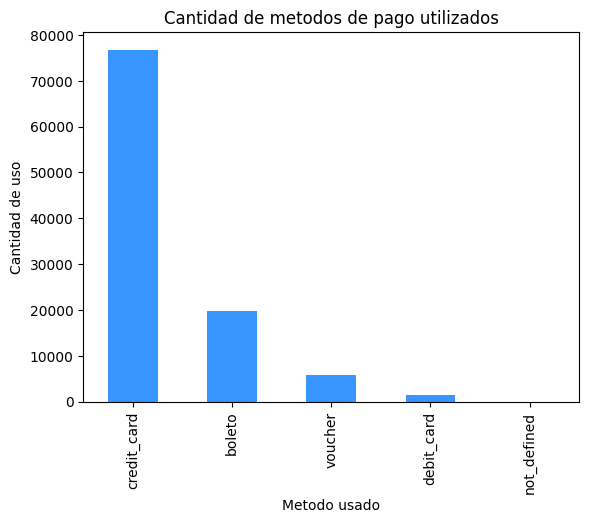

In [20]:
metodo_de_pago = payments["payment_type"].value_counts()
ax6 = metodo_de_pago.plot(kind="bar",
                          title= "Cantidad de metodos de pago utilizados",
                          color = "#0077ffc6",
                          ylabel = "Cantidad de uso",
                          xlabel = "Metodo usado")
plt.show()

El método de pago más utilizado es la tarjeta de credito

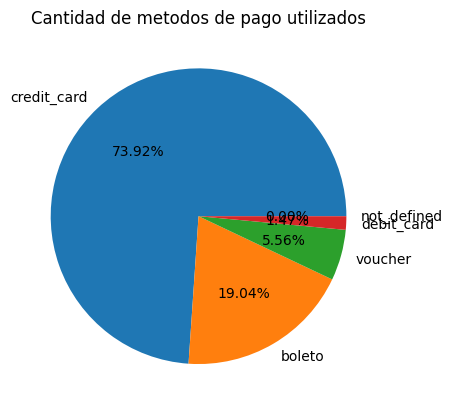

In [21]:
ax6_1 = metodo_de_pago.plot(kind = "pie",
                            title = "Cantidad de metodos de pago utilizados",
                            autopct = "%1.2f%%",
                            ylabel = "")
plt.show()

#### ¿Cuál de las dos gráficas permite comparar mejor los métodos de pago?
La gráfica de barras nos ayuda a comparar mejor los métodos de pago, sobre todo cuando la cantidad de uso es pequeña
#### ¿Cuál utilizarías si quisieras enfatizar la proporción que representa cada método?
 Yo utilizaría la gráfica de pastel porque muestra qué parte del total de pagos representa cada método

# 7 Número de cuotas

Utilizando la información de pagos, analiza la cantidad de cuotas registrada en payment_installments.

Agrupa las compras por número de cuotas y construye una gráfica de barras.

Pregunta: ¿Qué número de cuotas es el más frecuente?

Reto: Muestra únicamente los valores correspondientes a 1 a 10 cuotas.

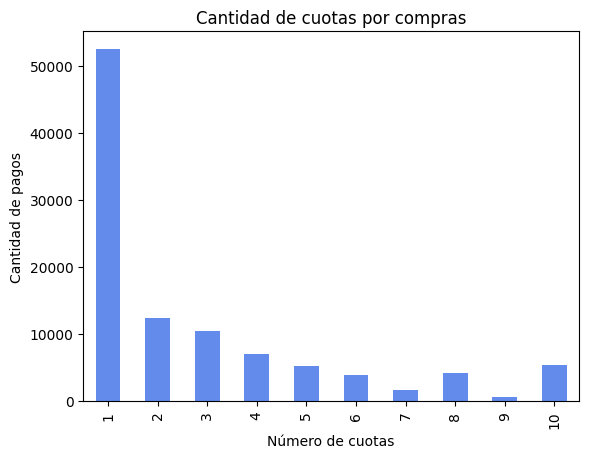

In [22]:
cantidad_cuotas = payments["payment_installments"].value_counts().sort_index().iloc[1:11]
ax6 = cantidad_cuotas.plot(kind="bar",
                             title = "Cantidad de cuotas por compras",
                             color = "#628beb",
                             xlabel="Número de cuotas",
                             ylabel= "Cantidad de pagos")
plt.show()


El numero de cuotas más frecuente es 1 cuota

# 8 Comparando visualizaciones

Utiliza la variable payment_type para construir:

Una gráfica de barras.
Un pie chart.

Las dos gráficas deben representar exactamente los mismos datos.

Pregunta: ¿Cuál utilizarías en un reporte para comparar los métodos de pago?

Pregunta: ¿Cuál utilizarías si quisieras enfatizar la proporción que representa cada método?



Reto de personalización

Personaliza tus gráficas utilizando las herramientas que hemos aprendido de Matplotlib.

ax.set_title(...)

ax.set_xlabel(...)

ax.set_ylabel(...)

También puedes experimentar con:

plt.xticks(...)

plt.show()

Para las barras, experimenta utilizando diferentes colores.

In [23]:
payments.columns

Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='object')

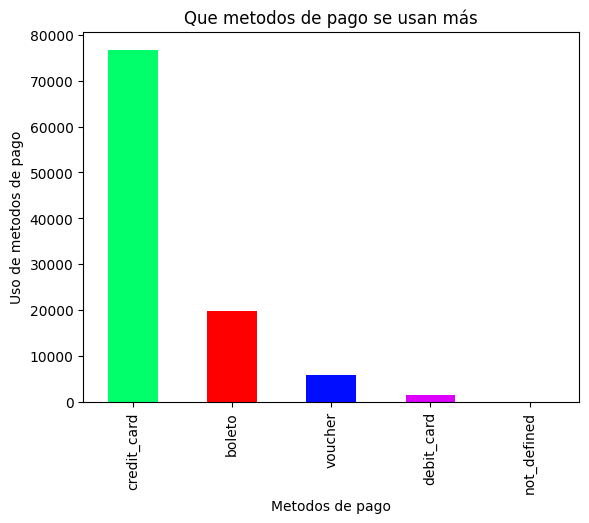

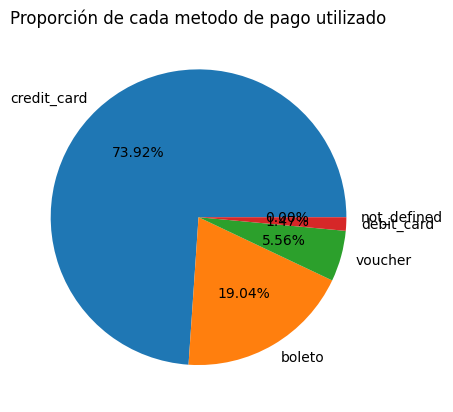

In [24]:
comparacion = payments["payment_type"].value_counts()
ax7 = comparacion.plot(kind= "bar",
                       color =[ "#00ff6a","#ff0000","#000dff","#dd00ff"])
ax7.set_title("Que metodos de pago se usan más")
ax7.set_xlabel("Metodos de pago")
ax7.set_ylabel("Uso de metodos de pago")
plt.show()
ax7_2 = comparacion.plot(kind = "pie",
                        color = "",
                        autopct = "%1.2f%%")
ax7_2.set_title("Proporción de cada metodo de pago utilizado")
ax7_2.set_ylabel("")
plt.show()

PREGUNTA 1: Para comparar los métodos de pago utilizaría la gráfica de barras porque se puede ordenar de mayor a menor y al ojo humano le es más facil distinguir las longitudes desde una misma linea base

PREGUNTA 2: Para enfatizar la proporción utilizaría la gráfica de pastel porque principalmente la gráfica de pastel siempre representa al 100% del total, por lo tanto cada particion de esta es un porcentaje de ese total, sumado a esto, para el humano le es muy facil diferenciar proporciones de un medio, un cuarto o tres cuartos, pero no puede diferenciar entre una proporción de un 20% y un 18%, por eso mismo agregamos los porcentajes en cada una de las particiones para facilitar la lectura de esta